# NIfTI 与 ROI 基础提取

按 **Shift+Enter** 从上到下逐单元运行。变量保留在当前内核中；如果修改上游参数，请重新运行其后的单元。

本教程使用固定合成数据，演示软件流程，不提供临床效能结论。需要完整仓库和对应原生安装包；实际源码版本和原生扩展身份请查看本次执行收据。

## 1. 环境与独立输出目录

确认后端为 Rust。后续每步都可以检查中间对象；示例数据生成辅助函数只负责小型输入构造。

In [1]:
from pathlib import Path
import sys, tempfile
from IPython.display import display, Image
# 从 Notebook 所在目录或仓库根目录启动均可。
REPO = Path(TUTORIAL_REPO_ROOT).resolve() if 'TUTORIAL_REPO_ROOT' in globals() else next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'examples/native/_shared.py').exists()), None)
if REPO is None:
    raise RuntimeError('请先下载完整仓库，并在仓库内启动 Jupyter。')
sys.path.insert(0, str(REPO/'examples/native'))
import ov_radiomics as rad
print(rad.backend_info())
# 每次完整运行使用新目录，避免覆盖已有结果。
output = Path(TUTORIAL_RUN_ROOT) if 'TUTORIAL_RUN_ROOT' in globals() else Path(tempfile.mkdtemp(prefix='radiomics-01_extract-'))
if 'TUTORIAL_RUN_ROOT' in globals():
    output.mkdir(parents=True, exist_ok=False)
root = output
print('输出目录:', output)
import hashlib, importlib.metadata, json, platform
runtime = {'interpreter': sys.executable, 'python': platform.python_version(),
           'package_source': rad.__file__, 'backend': rad.backend_info(),
           'packages': {name: importlib.metadata.version(name) for name in
                        ('ov-radiomics', 'numpy', 'pandas', 'matplotlib', 'ipykernel')}}
from ov_radiomics._backend import try_native
extension = try_native()
if extension is None:
    raise RuntimeError('本教程需要真实 Rust 原生扩展。')
runtime['native_path'] = extension.__file__
runtime['native_sha256'] = hashlib.sha256(Path(extension.__file__).read_bytes()).hexdigest()
runtime['package_python_sha256'] = {p.relative_to(Path(rad.__file__).parent).as_posix(): hashlib.sha256(p.read_bytes()).hexdigest()
                                  for p in sorted(Path(rad.__file__).parent.rglob('*.py'))}
(output/'tutorial-runtime.json').write_text(json.dumps(runtime, ensure_ascii=False, indent=2), encoding='utf-8')
 
import argparse
import csv
import json
import os
from pathlib import Path
import struct
import subprocess
import pandas as pd
import ov_radiomics as rad
def write_nifti(path, values):
    header = bytearray(352)
    struct.pack_into('<i', header, 0, 348)
    struct.pack_into('<8h', header, 40, 3, 6, 5, 4, 1, 1, 1, 1)
    struct.pack_into('<hh', header, 70, 64, 64)
    struct.pack_into('<8f', header, 76, 1, 2, 3, 4, 1, 1, 1, 1)
    struct.pack_into('<ff', header, 108, 352, 1)
    header[123] = 2
    struct.pack_into('<h', header, 254, 1)
    struct.pack_into('<4f', header, 280, -2, 0, 0, 10)
    struct.pack_into('<4f', header, 296, 0, 3, 0, -20)
    struct.pack_into('<4f', header, 312, 0, 0, 4, 30)
    header[344:348] = b'n+1\x00'
    path.write_bytes(header + struct.pack('<' + 'd' * len(values), *values))

{'metrics_backend': 'rust', 'rust_core_version': '0.1.0'}
输出目录: D:\radiomics-tutorial-validation\six-notebooks-final\01_extract\artifacts


## 2. 准备数据与保存中间结果

运行并检查本步的数据构造、校验或导出操作。遇到报错时先检查上一单元的输出和对象，而不要跳过校验。

In [2]:
(root / 'inputs').mkdir()
records = []
coordinates = [(x, y, z) for z in range(4) for y in range(5) for x in range(6)]
for index in range(3):
    sample = f'S{index + 1:03}'
    write_nifti(root / f'inputs/{sample}.nii', [x + 2 * y + 3 * z + index for (x, y, z) in coordinates])
    write_nifti(root / f'inputs/{sample}_roi.nii', [int(1 <= x <= 4 and 1 <= y <= 3 and (1 <= z <= 2)) for (x, y, z) in coordinates])
    records.append(dict(sample_id=sample, patient_id=f'P{(1 if index < 2 else 2):03}', image=f'inputs/{sample}.nii', mask=f'inputs/{sample}_roi.nii', modality='synthetic', region='tumor'))

## 3. 导出并读取队列清单

清单关联样本、患者、影像与 ROI。路径相对 CSV 解析，检查每条记录是否对应正确文件。

In [3]:
cohort = root / 'cohort.csv'
with cohort.open('w', newline='', encoding='utf-8') as handle:
    writer = csv.DictWriter(handle, fieldnames=list(records[0]))
    writer.writeheader()
    writer.writerows(records)

## 4. 显式提取参数

Original 特征，固定分箱参数和方向聚合方式。示例参数不代表所有 CT/MR/PET 的通用推荐。

In [4]:
config = dict(extraction=dict(profile='python_golden_v1', discretization=dict(method='fixed_width', width=2.0), aggregation='direction_mean', gldm_alpha=0, voxel_array_shift=0.0), labels=[1], preparation=[])
(root / 'extract.json').write_text(json.dumps(config, indent=2), encoding='utf-8')

274

## 5. 执行原生分析并检查结果

阅读本单元的核心调用与参数。模型训练只使用训练队列；评价时显式保留患者单位和队列身份。

In [5]:
result = rad.extract(rad.read_cohort(cohort), params=config, backend='rust', profile='python_golden_v1')
result.save(root / 'python-api')
assert result.features.original_shape_basic_VoxelCount.eq(24).all()
assert result.features.original_shape_basic_Volume_mm3.eq(576).all()
print(result.features[['ID', 'original_firstorder_Mean', 'original_shape_basic_VoxelCount', 'original_shape_basic_Volume_mm3']].to_string(index=False))

  ID  original_firstorder_Mean  original_shape_basic_VoxelCount  original_shape_basic_Volume_mm3
S001                      11.0                             24.0                            576.0
S002                      12.0                             24.0                            576.0
S003                      13.0                             24.0                            576.0


## 6. 准备数据与保存中间结果

运行并检查本步的数据构造、校验或导出操作。遇到报错时先检查上一单元的输出和对象，而不要跳过校验。

In [6]:
print('Outputs:', root)

Outputs: D:\radiomics-tutorial-validation\six-notebooks-final\01_extract\artifacts


## 用实际结果绘图

仅展示本次合成数据计算结果；请核对患者层级、坐标与单位。

In [7]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
frame = result.features
axes[0].bar(frame['ID'], frame['original_firstorder_Mean'])
axes[0].set(xlabel='Synthetic sample', ylabel='Mean (synthetic intensity units)')
axes[1].bar(frame['ID'], frame['original_shape_basic_Volume_mm3'])
axes[1].set(xlabel='Synthetic sample', ylabel='ROI volume (mm³)')
fig.tight_layout()
fig.savefig(output/'extraction-results.png', dpi=140)
plt.close(fig)

## 查看导出的图与文件

查看图表的坐标、单位和预测层级。输出目录保留完整结果；这里显示前两幅图。

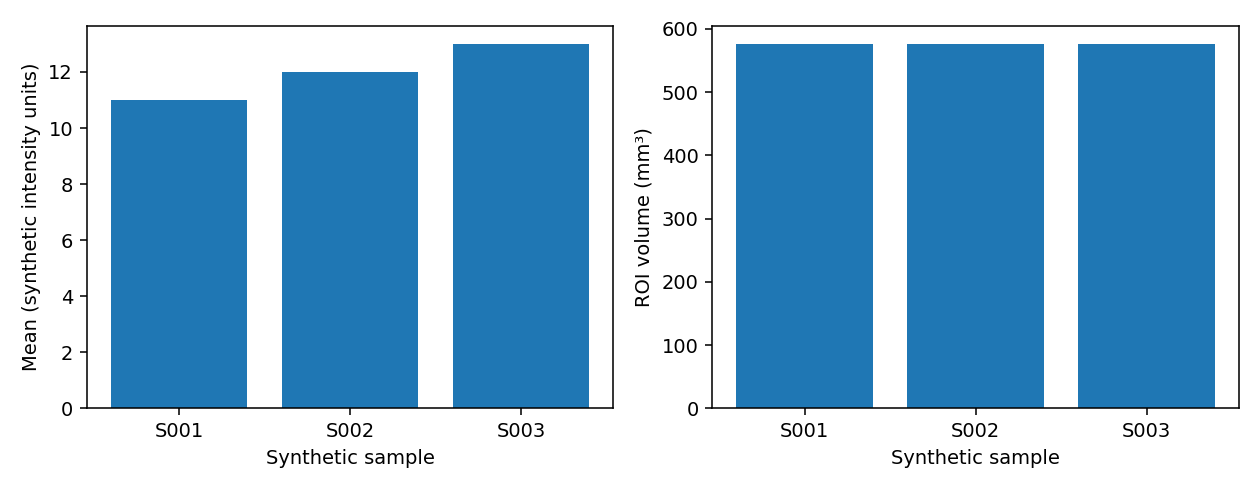

结果文件: ['cohort.csv', 'extract.json', 'extraction-results.png', 'inputs', 'python-api', 'tutorial-runtime.json']


In [8]:
for figure in sorted(output.glob('*.png'))[:2]:
    display(Image(filename=str(figure)))
print('结果文件:', [p.name for p in sorted(output.iterdir())])

## 换成自己的数据

保持示例的 ID、患者/切片层级与列角色约定，先替换数据读取步骤，再重新运行下游单元。先确认几何、单位、缺失状态和队列重叠；不要用测试集决定阈值或筛选参数。

重新运行全部单元会新建结果目录；只重跑保存单元可能因为文件已存在而报错，这是显式防覆盖行为。